# Gemini version of Fig 3A — drawing similarity to adults, by age

Parallel to the drawing-similarity panel of `06_correlation_analysis` (R/ggplot2),
using `data/preprocessed/gemini/draw_cossim_adults.csv` instead of the CLIP tidy
data. Same filter (children with >=3 valid category trials) and same per-child
z-scoring. Interference trials are excluded, as in the CLIP analyses.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

IN_CSV = "../data/preprocessed/gemini/draw_cossim_adults.csv"
OUT_PNG = "../figures/gemini_cds_drawing_sim.png"

# Interference trials (flagged in the tidy data) are excluded, as in the CLIP analyses
def interference_keys(path, col):
    t = pd.read_csv(path)
    return set(zip(t.loc[t[col] == 1, "participant_id"], t.loc[t[col] == 1, "target_category"]))


DRAW_INTERFERENCE = interference_keys("../data/tidy/drawings.csv", "draw_interference")
UTT_INTERFERENCE = interference_keys("../data/tidy/utterances.csv", "utterance_interference")


def drop_interference(df, keys):
    return df[[k not in keys for k in zip(df["participant_id"], df["target_category"])]].copy()

In [2]:
df = drop_interference(pd.read_csv(IN_CSV), DRAW_INTERFERENCE)

# Same filter as 06_correlation_analysis: children with >=3 valid category trials
valid_counts = df.groupby("participant_id")["draw_cossim_adults"].apply(lambda s: s.notna().sum())
keep_ids = valid_counts[valid_counts >= 3].index
df = df[df["participant_id"].isin(keep_ids)]

# Per-child mean across categories, then z-score across children
per_child = (
    df.groupby("participant_id")
    .agg(age_months=("age_months", "first"), mean_sim=("draw_cossim_adults", "mean"))
    .reset_index()
)
n_missing_age = per_child["age_months"].isna().sum()
if n_missing_age:
    print(f"dropping {n_missing_age} child(ren) with missing age_months: "
          f"{per_child.loc[per_child['age_months'].isna(), 'participant_id'].tolist()}")
    per_child = per_child.dropna(subset=["age_months"]).reset_index(drop=True)

per_child["sim_z"] = (per_child["mean_sim"] - per_child["mean_sim"].mean()) / per_child["mean_sim"].std(ddof=1)
per_child["age_years"] = per_child["age_months"] / 12

print(f"{len(per_child)} children")
per_child.head()

dropping 2 child(ren) with missing age_months: ['BD085', 'BD097']
85 children


,participant_id,age_months,mean_sim,sim_z,age_years
0,BD025,134.0,0.919330,0.776288,11.166667
1,BD026,124.0,0.950113,1.439370,10.333333
2,BD027,107.0,0.912150,0.621630,8.916667
3,BD028,91.0,0.919884,0.788224,7.583333
4,BD029,84.0,0.898301,0.323317,7.000000


In [ ]:
# Linear fit + approximate 95% CI band for the mean prediction 
x = per_child["age_years"].to_numpy()
y = per_child["sim_z"].to_numpy()
n = len(x)

xbar, ybar = x.mean(), y.mean()
Sxx = np.sum((x - xbar) ** 2)
b = np.sum((x - xbar) * (y - ybar)) / Sxx
a = ybar - b * xbar

resid = y - (a + b * x)
s2 = np.sum(resid ** 2) / (n - 2)
r = np.corrcoef(x, y)[0, 1]

x_grid = np.linspace(x.min(), x.max(), 100)
y_hat = a + b * x_grid
se_mean = np.sqrt(s2 * (1 / n + (x_grid - xbar) ** 2 / Sxx))
z_crit = 1.96  # normal approximation to the t-critical value
ci_lo, ci_hi = y_hat - z_crit * se_mean, y_hat + z_crit * se_mean

print(f"slope = {b:.4f} SD/year, Pearson r = {r:.3f}, n = {n}")

slope = 0.2984 SD/year, Pearson r = 0.687, n = 85


saved -> ../figures/gemini_cds_drawing_sim.png


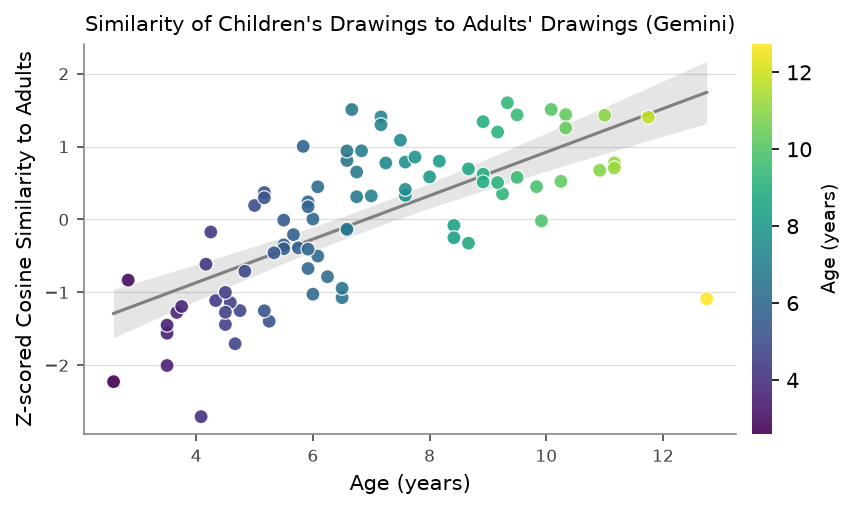

In [4]:
plt.rcParams["font.family"] = "sans-serif"
fig, ax = plt.subplots(figsize=(6, 3.5), dpi=150)

sc = ax.scatter(x, y, c=per_child["age_years"], cmap="viridis",
                 s=45, alpha=0.9, linewidths=0.6, edgecolors="white", zorder=3)
ax.fill_between(x_grid, ci_lo, ci_hi, color="grey", alpha=0.2, zorder=1, linewidth=0)
ax.plot(x_grid, y_hat, color="grey", linewidth=1.5, zorder=2)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Age (years)", size=9)
cbar.outline.set_visible(False)

ax.set_xlabel("Age (years)")
ax.set_ylabel("Z-scored Cosine Similarity to Adults")
ax.set_title("Similarity of Children's Drawings to Adults' Drawings (Gemini)", fontsize=10)

for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_color("#888888")
    ax.spines[spine].set_linewidth(0.8)
ax.tick_params(colors="#444444", labelsize=8)
ax.yaxis.grid(True, color="#dddddd", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(OUT_PNG, dpi=200)
print(f"saved -> {OUT_PNG}")
plt.show()

## Fig 3B — description similarity to adults, by age

Using `talk_cossim_adults.csv` (04bg), we can ask how gemini embeddings compare when quantifying children's descriptions cossim to adults. 
`utterance_full_cossim_adults`: same >=3-valid-trials filter, same per-child mean
then z-score, same fit/plot code.

In [5]:
IN_CSV_DESC = "../data/preprocessed/gemini/talk_cossim_adults.csv"
OUT_PNG_DESC = "../figures/gemini_cds_description_sim.png"

df_desc = drop_interference(pd.read_csv(IN_CSV_DESC), UTT_INTERFERENCE)

valid_counts_desc = df_desc.groupby("participant_id")["utterance_full_cossim_adults"].apply(lambda s: s.notna().sum())
keep_ids_desc = valid_counts_desc[valid_counts_desc >= 3].index
df_desc = df_desc[df_desc["participant_id"].isin(keep_ids_desc)]

per_child_desc = (
    df_desc.groupby("participant_id")
    .agg(age_months=("age_months", "first"), mean_sim=("utterance_full_cossim_adults", "mean"))
    .reset_index()
)
n_missing_age_desc = per_child_desc["age_months"].isna().sum()
if n_missing_age_desc:
    dropped = per_child_desc.loc[per_child_desc["age_months"].isna(), "participant_id"].tolist()
    print(f"dropping {n_missing_age_desc} child(ren) with missing age_months: {dropped}")
    per_child_desc = per_child_desc.dropna(subset=["age_months"]).reset_index(drop=True)

per_child_desc["sim_z"] = (per_child_desc["mean_sim"] - per_child_desc["mean_sim"].mean()) / per_child_desc["mean_sim"].std(ddof=1)
per_child_desc["age_years"] = per_child_desc["age_months"] / 12

print(f"{len(per_child_desc)} children")
per_child_desc.head()

72 children


,participant_id,age_months,mean_sim,sim_z,age_years
0,BD025,134.0,0.873015,0.342722,11.166667
1,BD026,124.0,0.907497,1.175290,10.333333
2,BD027,107.0,0.894176,0.853658,8.916667
3,BD028,91.0,0.868659,0.237558,7.583333
4,BD029,84.0,0.886535,0.669165,7.000000


In [6]:
#Compute residual variance and correlation for description similarity 
x_d = per_child_desc["age_years"].to_numpy()
y_d = per_child_desc["sim_z"].to_numpy()
n_d = len(x_d)

xbar_d, ybar_d = x_d.mean(), y_d.mean()
Sxx_d = np.sum((x_d - xbar_d) ** 2)
b_d = np.sum((x_d - xbar_d) * (y_d - ybar_d)) / Sxx_d
a_d = ybar_d - b_d * xbar_d

resid_d = y_d - (a_d + b_d * x_d)
s2_d = np.sum(resid_d ** 2) / (n_d - 2)
r_d = np.corrcoef(x_d, y_d)[0, 1]

x_grid_d = np.linspace(x_d.min(), x_d.max(), 100)
y_hat_d = a_d + b_d * x_grid_d
se_mean_d = np.sqrt(s2_d * (1 / n_d + (x_grid_d - xbar_d) ** 2 / Sxx_d))
z_crit = 1.96
ci_lo_d, ci_hi_d = y_hat_d - z_crit * se_mean_d, y_hat_d + z_crit * se_mean_d

print(f"slope = {b_d:.4f} SD/year, Pearson r = {r_d:.3f}, n = {n_d}")

slope = 0.2817 SD/year, Pearson r = 0.600, n = 72


saved -> ../figures/gemini_cds_description_sim.png


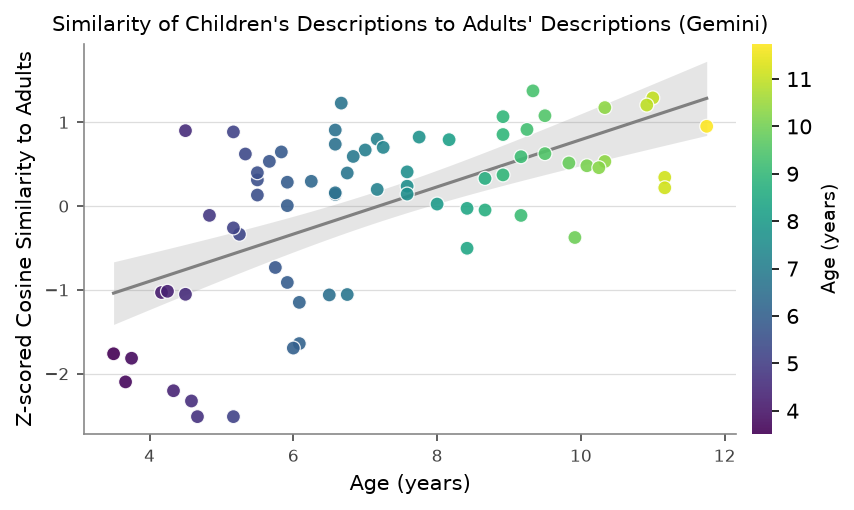

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5), dpi=150)

sc = ax.scatter(x_d, y_d, c=per_child_desc["age_years"], cmap="viridis",
                 s=45, alpha=0.9, linewidths=0.6, edgecolors="white", zorder=3)
ax.fill_between(x_grid_d, ci_lo_d, ci_hi_d, color="grey", alpha=0.2, zorder=1, linewidth=0)
ax.plot(x_grid_d, y_hat_d, color="grey", linewidth=1.5, zorder=2)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Age (years)", size=9)
cbar.outline.set_visible(False)

ax.set_xlabel("Age (years)")
ax.set_ylabel("Z-scored Cosine Similarity to Adults")
ax.set_title("Similarity of Children's Descriptions to Adults' Descriptions (Gemini)", fontsize=10)

for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_color("#888888")
    ax.spines[spine].set_linewidth(0.8)
ax.tick_params(colors="#444444", labelsize=8)
ax.yaxis.grid(True, color="#dddddd", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(OUT_PNG_DESC, dpi=200)
print(f"saved -> {OUT_PNG_DESC}")
plt.show()

## Fig 4 — drawing vs. description similarity, by category

Outer join of `draw_cossim_adults.csv` and `talk_cossim_adults.csv` on
(`participant_id`, `age_months`, `target_category`), kept to rows where both
similarities exist. Unlike Fig 3A/3B, z-scoring here is done at the row (child x
category) because we are interested in comparing between categories.

In [8]:
draw_wide = drop_interference(pd.read_csv("../data/preprocessed/gemini/draw_cossim_adults.csv"), DRAW_INTERFERENCE)[
    ["participant_id", "age_months", "target_category", "draw_cossim_adults"]
].rename(columns={"draw_cossim_adults": "drawing_similarity"})

desc_wide = drop_interference(pd.read_csv("../data/preprocessed/gemini/talk_cossim_adults.csv"), UTT_INTERFERENCE)[
    ["participant_id", "age_months", "target_category", "utterance_full_cossim_adults"]
].rename(columns={"utterance_full_cossim_adults": "description_similarity"})

wide = draw_wide.merge(desc_wide, on=["participant_id", "age_months", "target_category"], how="outer")
print("joined rows:", len(wide))
print("rows with both similarities present:", wide[["drawing_similarity", "description_similarity"]].notna().all(axis=1).sum())

joined rows: 511
rows with both similarities present: 411


In [9]:
kids_both = wide.dropna(subset=["drawing_similarity", "description_similarity"]).copy()
kids_both["drawing_sim_z"] = (kids_both["drawing_similarity"] - kids_both["drawing_similarity"].mean()) / kids_both["drawing_similarity"].std(ddof=1)
kids_both["description_sim_z"] = (kids_both["description_similarity"] - kids_both["description_similarity"].mean()) / kids_both["description_similarity"].std(ddof=1)
kids_both["age_years"] = kids_both["age_months"] / 12

print(f"Total observations: {len(kids_both)}")
print(f"Number of children: {kids_both['participant_id'].nunique()}")
print(kids_both["target_category"].value_counts())

Total observations: 411
Number of children: 77
target_category
turtle      71
whale       70
shark       69
seahorse    68
octopus     67
crab        66
Name: count, dtype: int64


saved -> ../figures/gemini_cds_similarity_by_age_by_category.png


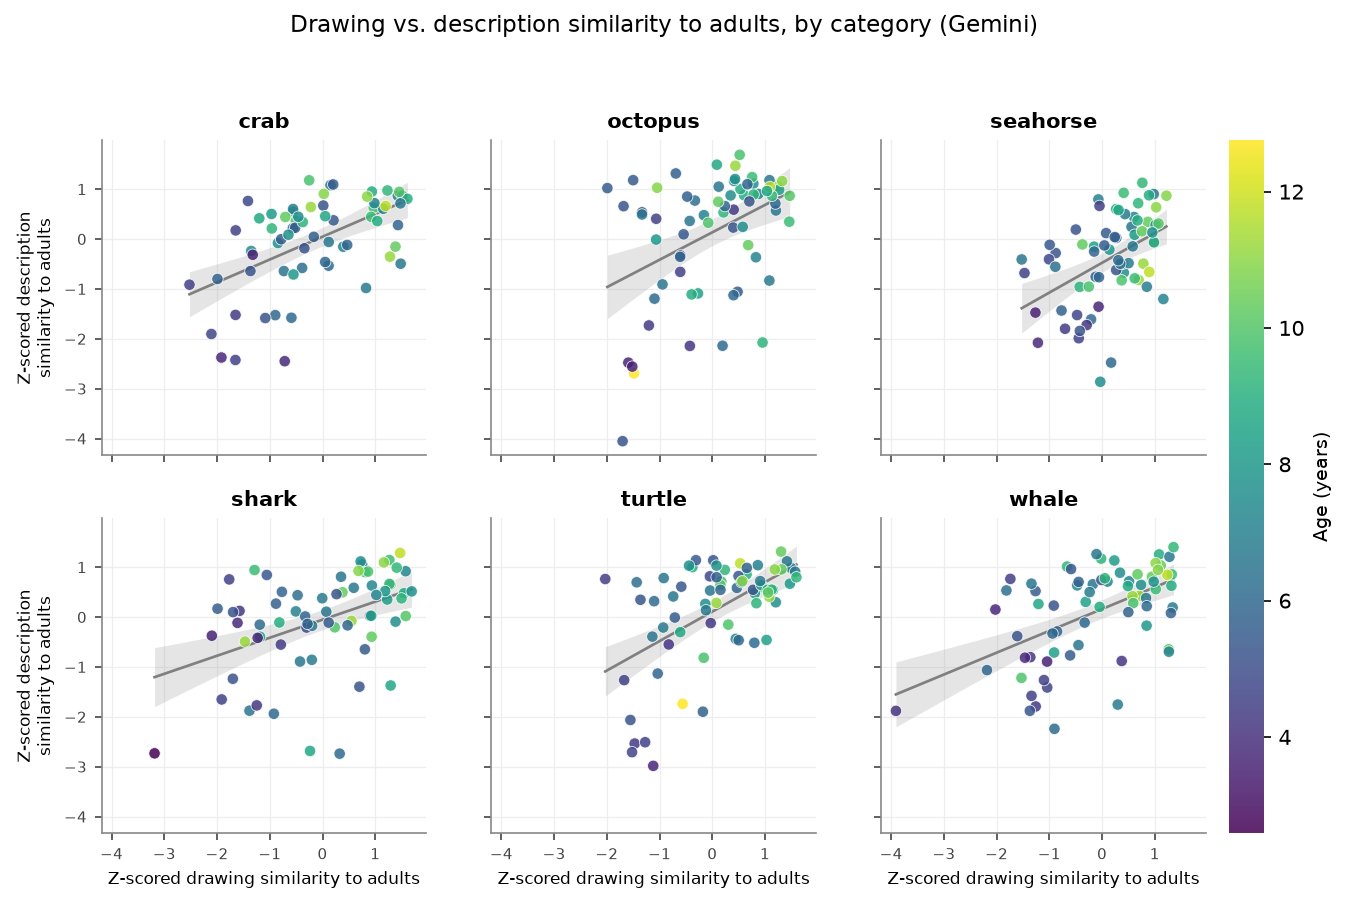

In [10]:
CATEGORIES = ["crab", "octopus", "seahorse", "shark", "turtle", "whale"]
OUT_PNG_FIG4 = "../figures/gemini_cds_similarity_by_age_by_category.png"

fig, axes = plt.subplots(2, 3, figsize=(10, 6), dpi=150, sharex=True, sharey=True)
vmin_age, vmax_age = kids_both["age_years"].min(), kids_both["age_years"].max()

for ax, cat in zip(axes.flat, CATEGORIES):
    sub = kids_both[kids_both["target_category"] == cat]
    xs = sub["drawing_sim_z"].to_numpy()
    ys = sub["description_sim_z"].to_numpy()
    sc = ax.scatter(xs, ys, c=sub["age_years"], cmap="viridis", vmin=vmin_age, vmax=vmax_age,
                     s=30, alpha=0.85, linewidths=0.4, edgecolors="white", zorder=3)

    nx = len(xs)
    if nx > 2:
        xbar_f, ybar_f = xs.mean(), ys.mean()
        Sxx_f = np.sum((xs - xbar_f) ** 2)
        if Sxx_f > 0:
            b_f = np.sum((xs - xbar_f) * (ys - ybar_f)) / Sxx_f
            a_f = ybar_f - b_f * xbar_f
            resid_f = ys - (a_f + b_f * xs)
            s2_f = np.sum(resid_f ** 2) / max(nx - 2, 1)
            xg = np.linspace(xs.min(), xs.max(), 50)
            yg = a_f + b_f * xg
            se_f = np.sqrt(s2_f * (1 / nx + (xg - xbar_f) ** 2 / Sxx_f))
            ax.fill_between(xg, yg - 1.96 * se_f, yg + 1.96 * se_f, color="grey", alpha=0.2, zorder=1, linewidth=0)
            ax.plot(xg, yg, color="grey", linewidth=1.3, zorder=2)

    ax.set_title(cat, fontsize=10, fontweight="bold")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color("#888888")
        ax.spines[spine].set_linewidth(0.8)
    ax.tick_params(colors="#444444", labelsize=7)
    ax.grid(True, color="#eeeeee", linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)

for ax in axes[-1]:
    ax.set_xlabel("Z-scored drawing similarity to adults", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Z-scored description\nsimilarity to adults", fontsize=8)

cbar = fig.colorbar(sc, ax=axes, pad=0.02, fraction=0.03)
cbar.set_label("Age (years)", size=9)
cbar.outline.set_visible(False)

fig.suptitle("Drawing vs. description similarity to adults, by category (Gemini)", fontsize=11, y=1.02)
fig.savefig(OUT_PNG_FIG4, dpi=200, bbox_inches="tight")
print(f"saved -> {OUT_PNG_FIG4}")
plt.show()

In [11]:
sub_avg_both = (
    kids_both.groupby("participant_id")
    .agg(avg_drawing_sim_z=("drawing_sim_z", "mean"),
         avg_description_sim_z=("description_sim_z", "mean"),
         age_months=("age_months", "first"))
    .reset_index()
)

overall_r = np.corrcoef(sub_avg_both["avg_drawing_sim_z"], sub_avg_both["avg_description_sim_z"])[0, 1]
print(f"Overall per-child correlation: r = {overall_r:.3f}, n = {len(sub_avg_both)}")

print("\nPer-category correlation (row-level, not per-child-averaged):")
for cat in CATEGORIES:
    sub = kids_both[kids_both["target_category"] == cat]
    if len(sub) > 2:
        r_cat = np.corrcoef(sub["drawing_sim_z"], sub["description_sim_z"])[0, 1]
        print(f"  {cat:10s} r = {r_cat:.3f}  n = {len(sub)}")

Overall per-child correlation: r = 0.732, n = 77

Per-category correlation (row-level, not per-child-averaged):
  crab       r = 0.543  n = 66
  octopus    r = 0.423  n = 67
  seahorse   r = 0.464  n = 68
  shark      r = 0.444  n = 69
  turtle     r = 0.549  n = 71
  whale      r = 0.531  n = 70
